Descarga el conjunto de datos de MNIST. 
X contiene las imagenes de los digitos, osease las matrices de pixeles.
Y contiene las labels, osease el numero que representa cada imagen.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Esta porción de codigo tiene multiples funciones:
- Primero se define el valor maxico que puede tener un pixel en una escala de grises.
- Se convierte a numeros flotantes para aumentar la presicion de la red neuronal.
- Se normaliza mediante una division, ayudando a la conversion.
- Imprime en consola las dimensiones de las matrices.

In [ ]:
gray_scale = 255

x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


Se selecciona la primera imagen del conjunto y accede a la fila 15 de la cuadricula, devolviendo un arreglo con 28 valores que corresponden a los pixeles de la misma.

In [ ]:
x_train[0][15]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.1764706 ,
       0.7294118 , 0.99215686, 0.99215686, 0.5882353 , 0.10588235,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        ], dtype=float32)

Extrae un fragmento de las etiquteas de entrenamiento, asignando cada una a su imagen. El modelo usa esto como una guia para aprender a asociar los dibujos con su numero correspondiente.

In [ ]:
y_train[0:10]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

Se utiliza una libreria para crear una cuadricula con imagenes para vizualizar los digitos escritos a mano con los que se esta entrenando el modelo.

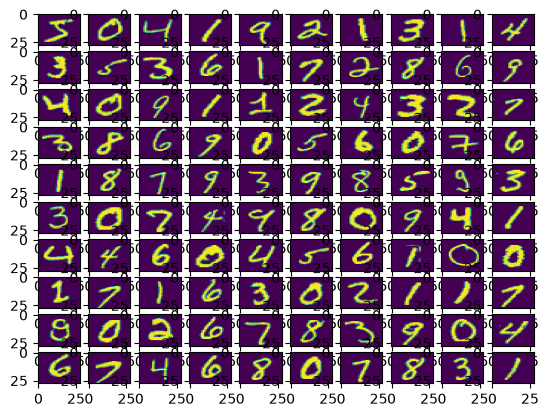

In [ ]:
fig, ax = plt.subplots(10, 10)
k = 0
for i in range(10):
    for j in range(10):
        ax[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show()

Aplica las capas del perceptron de forma lineal, para que se sigan una tras otra. Primero, aplana la matriz para convertirla en una sola fila larga. Despues, la capa recibe los valores de entrada, aprende pesos sinapticos y extrae los digitos para despues utilizar la funcion de activación sigmoid, la cual comprime los valores de salida de las neuronas en rangos binarios. 

La función de activación softmax se utiliza para la clasificación multiclase. Convierte los numeros de salida en probabilidades. La neurona con la probabilidad más alta será el numero que el modelo prediga como respuesta.

In [ ]:
model = Sequential([
    Flatten(input_shape=(28, 28)), #entrada de 28x28 pixeles
    Dense(256, activation='sigmoid'),
    Dense(128, activation='sigmoid'),
    Dense(10, activation='softmax'),
])

c:\Users\anapa\inteligencia-artificial\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Se prepara el modelo para que pueda aprender configurando tres aspectos matematicos fundamentales:
- Utiliza el optimizador Adam (Adaptive moment estimation), el cual es un algoritmo de deep learning, y se encarga de actualizar y ajustar los pesos de la red de manera optima en funcion de los errores detectados.
- La función de perdida mide que tan equivocadas o acertadas son las predicciones comparadas con las labels.
- Metrics define la metrica que se usara para evualuar el rendimiento del modelo, indicando la presicioón de éste.

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Aquí es donde el perceptron aprende. Se le dan los datos de entrada (imagenes y su respectivo label), la cantidad de epocas por las que aprendera, y el tamaño del lote en el que procesara las imagenes cada epoca. Despues, separa el 20% de los datos para usarlos como validacion de cada epoca, usandolos para evaluar su desempeño.

In [ ]:
mod = model.fit(x_train, y_train, epochs=10, 
          batch_size=2000, 
          validation_split=0.2)
          
print(mod)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9973 - loss: 0.0187 - val_accuracy: 0.9760 - val_loss: 0.0837
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9975 - loss: 0.0181 - val_accuracy: 0.9763 - val_loss: 0.0830
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9975 - loss: 0.0172 - val_accuracy: 0.9760 - val_loss: 0.0830
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9978 - loss: 0.0165 - val_accuracy: 0.9765 - val_loss: 0.0823
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9979 - loss: 0.0160 - val_accuracy: 0.9756 - val_loss: 0.0829
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9981 - loss: 0.0153 - val_accuracy: 0.9759 - val_loss: 0.0832
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9983 - loss: 0.0147 - val_accuracy: 0.9764 - val_loss: 0.0828
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9984 - loss: 0.0141 - val_accuracy: 0.9762 - v

In [ ]:
results = model.evaluate(x_test, y_test, verbose=0)
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.07263700664043427, 0.9768000245094299]


Impresión de los resultados.

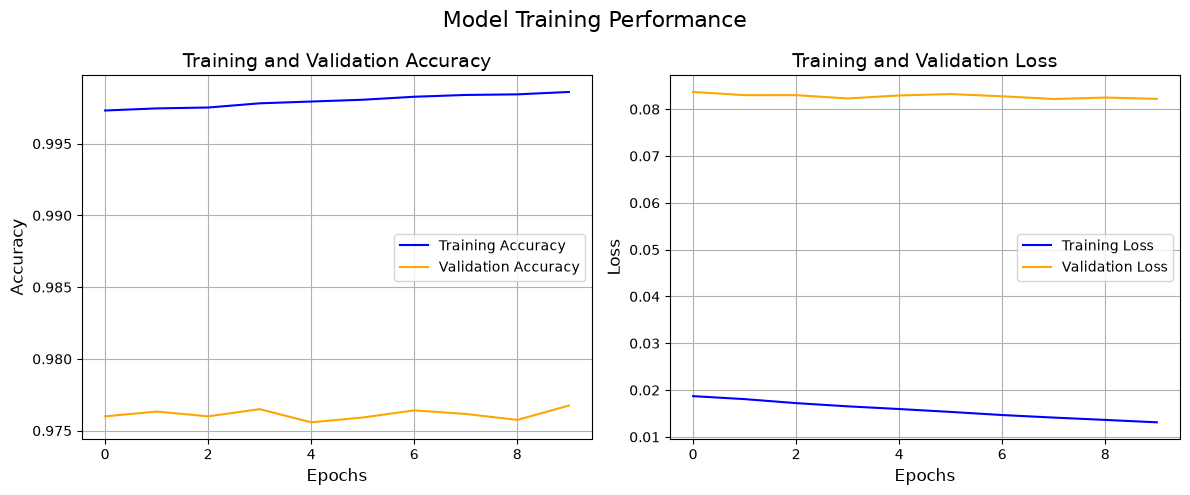

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mod.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mod.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(mod.history['loss'], label='Training Loss', color='blue')
plt.plot(mod.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
model.save('mlp_model.keras')

In [ ]:
import os
import tkinter as tk
from PIL import Image, ImageDraw
import numpy as np
import tensorflow as tf

# Se carga el modelo previamente entrenado.
ruta = "mlp_model.keras"
model = tf.keras.models.load_model(ruta)


# Configurar interfaz.
ventana = tk.Tk()
ventana.title("Reconocedor de Dígitos")
ventana.geometry("360#480".replace("#", "x"))
ventana.configure(bg="#004d40")

# Título
titulo = tk.Label(
    ventana,
    text="Dibuja un número (0-9)",
    font=("Arial", 14, "bold"),
    bg="#004d40",
    fg="#e0f2f1"
)
titulo.pack(pady=12)

# Lienzo para dibujar
canvas = tk.Canvas(
    ventana,
    width=280,
    height=280,
    bg="black",
    highlightthickness=2,
    highlightbackground="#00897b"
)
canvas.pack()

# Imagen auxiliar en memoria, asi se podra capturar lo que se dibuja 
# en el canvas y procesarlo para la predicción.
imagen_aux = Image.new("L", (280, 280), 0)
draw = ImageDraw.Draw(imagen_aux)


# Funciones de dibujo y predicción
# La función dibujar se activa cuando el usuario mantiene presionado el botón
# izquierdo del mouse y mueve el cursor sobre el canvas.
# Dibuja un círculo blanco en la posición del cursor y también actualiza la 
# imagen auxiliar en memoria.
def dibujar(event):
    x, y = event.x, event.y
    r = 12  # Grosor del pincel
    
    # Dibujar en pantalla y en memoria
    canvas.create_oval(x-r, y-r, x+r, y+r, fill="white", outline="white")
    draw.ellipse([x-r, y-r, x+r, y+r], fill=255)

canvas.bind("<B1-Motion>", dibujar)
canvas.bind("<Button-1>", dibujar)

def predecir():
    caja = imagen_aux.getbbox()
    if caja is None:
        lbl_resultado.config(text="¡Dibuja algo primero!")
        return

    # Procesar imagen
    # Recorta la iamgne para que sea unicamente el area trazada y la redimensiona.
    img = imagen_aux.crop(caja)
    img.thumbnail((20, 20), Image.Resampling.LANCZOS)
    
    # Crea un fondo negro y pega la imagen dibujada en el centro de esa cuadricula.
    fondo = Image.new("L", (28, 28), 0)
    fondo.paste(img, ((28 - img.width) // 2, (28 - img.height) // 2))

    # Convierte la imagen en una matriz numerica, la normaliza y ajusta.
    datos = np.array(fondo).astype("float32") / 255.0
    datos = datos.reshape(1, 28, 28)

    # Predicción del modelo
    # Le pasa los datos a la red neuronal y devuelve un arreglo con 10 probabilidades.
    # Despues, se busca cual de esas es más alta.
    pred = model.predict(datos, verbose=0)
    numero = np.argmax(pred)

    lbl_resultado.config(text=f"Resultado: {numero}")

def limpiar():
    canvas.delete("all")
    draw.rectangle([0, 0, 280, 280], fill=0)
    lbl_resultado.config(text="Resultado: ?")


# Botones y resultado
frame_botones = tk.Frame(ventana, bg="#004d40")
frame_botones.pack(pady=10)

btn_predecir = tk.Button(
    frame_botones, text="Predecir", command=predecir,
    font=("Arial", 11, "bold"), bg="#00897b", fg="white", width=10, relief="flat"
)
btn_predecir.grid(row=0, column=0, padx=5)

btn_limpiar = tk.Button(
    frame_botones, text="Limpiar", command=limpiar,
    font=("Arial", 11), bg="#b2dfdb", fg="#004d40", width=10, relief="flat"
)
btn_limpiar.grid(row=0, column=1, padx=5)

lbl_resultado = tk.Label(
    ventana,
    text="Resultado: ?",
    font=("Arial", 16, "bold"),
    bg="#004d40",
    fg="#e0f2f1"
)
lbl_resultado.pack(pady=5)

ventana.mainloop()